# 02 — La historia de los datos

**Pregunta:** ¿Qué perfiles de conductor y vehículo tienen mayor costo esperado de siniestros
(prima pura), y cuánto se apartan del promedio de la cartera?

Este notebook cuenta la historia en los **4 actos** de la presentación. Cada gráfico se guarda en
`presentacion/img/` para usarlo en las diapositivas: los números de la presentación salen de acá.

1. ¿Podemos confiar en los datos?
2. ¿Quién es más riesgoso?
3. ¿Cuánto debería costar cada perfil?
4. ¿Qué no podemos afirmar?

> Requisito: haber corrido `python src/load_raw.py` y `python src/build_core.py`.
> Trabajamos sobre la capa **core** (datos ya limpios).

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

conn = sqlite3.connect("../db/seguros.db")
IMG = Path("../presentacion/img")
IMG.mkdir(parents=True, exist_ok=True)

# --- Estilo común de los gráficos (una sola vez, así todos se ven iguales) ---
AZUL, GRIS, NARANJA, TINTA = "#2a78d6", "#a3a29c", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 160,
    "font.size": 13, "axes.titlesize": 16, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe7", "axes.axisbelow": True,
})

def guardar(fig, nombre):
    """Guarda el gráfico para la presentación y lo muestra."""
    fig.tight_layout()
    fig.savefig(IMG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

## Preparar los datos: una fila por póliza

Regla del TP (evita el *fan-out*): **primero agregamos los siniestros por póliza**, después unimos.

In [2]:
polizas = pd.read_sql("""
    SELECT p.*, d.region_2016, COALESCE(s.monto, 0) AS monto
    FROM core_poliza p
    JOIN core_dim_region d ON d.region_codigo = p.region
    LEFT JOIN (SELECT idpol, SUM(claimamount) AS monto
               FROM core_siniestro GROUP BY idpol) s ON s.idpol = p.idpol
""", conn)
siniestros = pd.read_sql("""
    SELECT s.idpol, s.claimamount, p.drivage, p.bonusmalus, p.area
    FROM core_siniestro s JOIN core_poliza p ON p.idpol = s.idpol
""", conn)
print(f"{len(polizas):,} pólizas y {len(siniestros):,} siniestros")

678,013 pólizas y 26,444 siniestros


### Franjas (agrupamos variables numéricas)

Comparar 83 edades distintas no se puede leer; las agrupamos en franjas.
En BonusMalus, **50 es el mejor nivel** (máxima bonificación) y **más de 100 es recargo** (malus).

In [3]:
polizas["franja_edad"] = pd.cut(polizas["drivage"], [17, 21, 25, 30, 40, 50, 60, 70, 200],
    labels=["18-21", "22-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71+"])
polizas["franja_bm"] = pd.cut(polizas["bonusmalus"], [49, 50, 75, 100, 400],
    labels=["50", "51-75", "76-100", "101+"])

# Indicadores globales de la cartera (la referencia "1,0" de las relatividades)
FREC_GLOBAL = polizas["claimnb"].sum() / polizas["exposure"].sum()
SEV_GLOBAL = polizas["monto"].sum() / polizas["claimnb"].sum()
PP_GLOBAL = polizas["monto"].sum() / polizas["exposure"].sum()
print(f"Frecuencia global: {FREC_GLOBAL:.4f} siniestros por año-póliza")
print(f"Severidad media:   {SEV_GLOBAL:,.2f}")
print(f"Prima pura global: {PP_GLOBAL:,.2f} por año-póliza")

Frecuencia global: 0.0738 siniestros por año-póliza
Severidad media:   2,265.51
Prima pura global: 167.18 por año-póliza


### Función para resumir cualquier segmento

Siempre igual: sumamos siniestros, montos y exposición **dentro del segmento** y dividimos.
Nunca promediamos `claimnb` (eso ignoraría cuánto tiempo estuvo cubierta cada póliza).

In [4]:
def resumen(df, columna, montos="monto"):
    g = df.groupby(columna, observed=True).agg(
        polizas=("idpol", "size"), exposicion=("exposure", "sum"),
        siniestros=("claimnb", "sum"), monto=(montos, "sum"))
    g["pct_exposicion"] = 100 * g["exposicion"] / g["exposicion"].sum()
    g["frecuencia"] = g["siniestros"] / g["exposicion"]
    g["severidad"] = g["monto"] / g["siniestros"]
    g["prima_pura"] = g["monto"] / g["exposicion"]
    g["rel_frecuencia"] = g["frecuencia"] / FREC_GLOBAL
    g["rel_prima_pura"] = g["prima_pura"] / (df[montos].sum() / df["exposure"].sum())
    return g

def barras_relatividad(tabla, col_rel, titulo, nombre, xlabel):
    """Barras de relatividad con la línea del promedio de la cartera en 1,0."""
    fig, ax = plt.subplots()
    etiquetas = [f"{i}\n{p:.0f}% expo." for i, p in zip(tabla.index, tabla["pct_exposicion"])]
    barras = ax.bar(etiquetas, tabla[col_rel], color=AZUL, width=0.6)
    ax.axhline(1, color=TINTA, linestyle="--", linewidth=1.2)
    ax.text(len(tabla) - 0.5, 1.03, "promedio de la cartera = 1,0", ha="right", va="bottom", color=TINTA, fontsize=11)
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in tabla[col_rel]], padding=3, fontsize=11)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("veces el promedio")
    guardar(fig, nombre)

---
# Acto 1 · ¿Podemos confiar en los datos?

Antes de comparar perfiles, conciliamos las dos tablas (detalle en `docs/04` y `docs/05`).
El hallazgo principal: **9.117 pólizas declaraban siniestros que no estaban en la tabla de montos**.
Si los usábamos, la frecuencia quedaba inflada.

Frecuencia antes: 0.1007 | después: 0.0738 | cambio: -27%
Coherencia antes:   frecuencia x severidad = 228 vs prima pura 167
Coherencia después: frecuencia x severidad = 167 vs prima pura 167


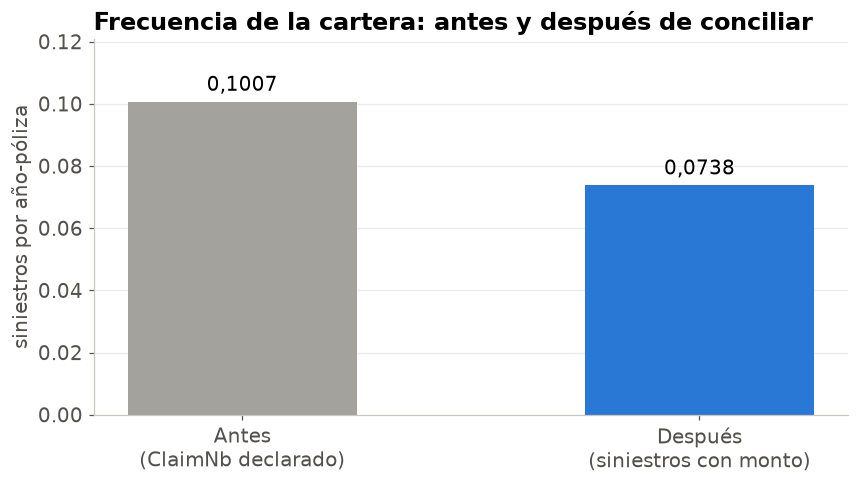

In [5]:
antes = pd.read_sql("SELECT SUM(claimnb) * 1.0 / SUM(exposure) AS f FROM raw_freq", conn)["f"][0]
despues = FREC_GLOBAL
print(f"Frecuencia antes: {antes:.4f} | después: {despues:.4f} | cambio: {100 * (despues / antes - 1):.0f}%")
print(f"Coherencia antes:   frecuencia x severidad = {antes * SEV_GLOBAL:,.0f} vs prima pura {PP_GLOBAL:,.0f}")
print(f"Coherencia después: frecuencia x severidad = {despues * SEV_GLOBAL:,.0f} vs prima pura {PP_GLOBAL:,.0f}")

fig, ax = plt.subplots(figsize=(8, 4.6))
barras = ax.bar(["Antes\n(ClaimNb declarado)", "Después\n(siniestros con monto)"], [antes, despues],
                color=[GRIS, AZUL], width=0.5)
ax.bar_label(barras, labels=[f"{v:.4f}".replace(".", ",") for v in (antes, despues)], padding=4, fontsize=13)
ax.set_title("Frecuencia de la cartera: antes y después de conciliar")
ax.set_ylabel("siniestros por año-póliza")
ax.set_ylim(0, antes * 1.2)
guardar(fig, "a1_frecuencia_antes_despues")

**Lectura:** la frecuencia baja de 0,1007 a 0,0738 (−27 %). Y recién después de corregir,
frecuencia × severidad coincide con la prima pura: los tres indicadores cuentan la misma historia.

---
# Acto 2 · ¿Quién es más riesgoso?

Medimos **frecuencia** (¿cada cuánto chocan?) como relatividad: 1,0 = promedio de la cartera.

### H1 — Edad del conductor

,polizas,pct_exposicion,frecuencia,rel_frecuencia
franja_edad,,,,
18-21,11253,1.229,0.211,2.865
22-25,27642,3.299,0.125,1.687
26-30,65594,8.139,0.082,1.105
31-40,170097,23.412,0.069,0.937
41-50,165185,24.584,0.076,1.024
51-60,135014,21.124,0.069,0.937
61-70,63863,10.693,0.062,0.834
71+,39365,7.519,0.060,0.810


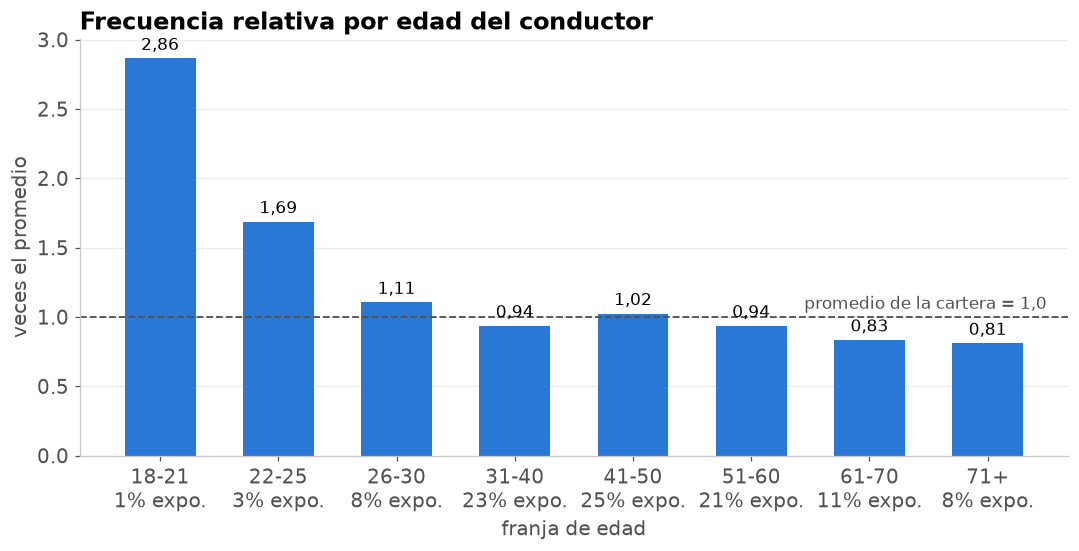

In [6]:
por_edad = resumen(polizas, "franja_edad")
display(por_edad[["polizas", "pct_exposicion", "frecuencia", "rel_frecuencia"]].round(3))
barras_relatividad(por_edad, "rel_frecuencia", "Frecuencia relativa por edad del conductor",
                   "a2_frecuencia_edad", "franja de edad")

**Lectura:** los conductores de 18–21 tienen casi **3 veces** la frecuencia promedio, y la de
22–25 también está arriba. Desde los 31 años la frecuencia queda cerca o por debajo del promedio.
Ojo con el tamaño: 18–21 es apenas el 1 % de la exposición.

### H1 — BonusMalus

,polizas,pct_exposicion,frecuencia,rel_frecuencia
franja_bm,,,,
50,384156,62.829,0.051,0.698
51-75,175012,23.672,0.092,1.251
76-100,111051,12.503,0.129,1.743
101+,7794,0.996,0.352,4.767


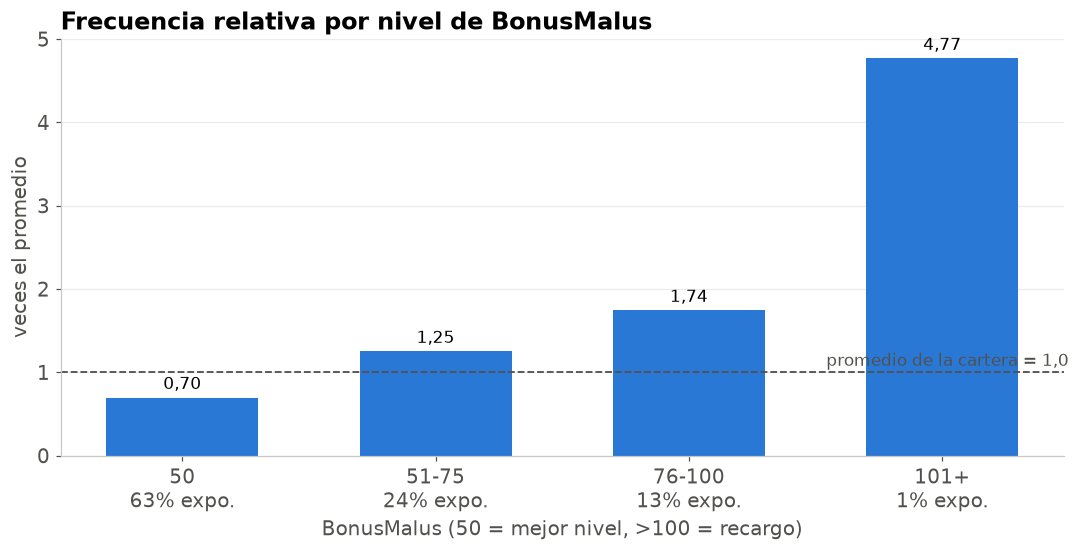

In [7]:
por_bm = resumen(polizas, "franja_bm")
display(por_bm[["polizas", "pct_exposicion", "frecuencia", "rel_frecuencia"]].round(3))
barras_relatividad(por_bm, "rel_frecuencia", "Frecuencia relativa por nivel de BonusMalus",
                   "a2_frecuencia_bm", "BonusMalus (50 = mejor nivel, >100 = recargo)")

**Lectura:** la frecuencia sube con el BonusMalus en forma ordenada: de 0,70 en el mejor nivel a
casi **4,8 veces** el promedio con recargo. Las dos variables separan el riesgo. Cuál pesa más (la pregunta de **H1**) se ve en el cruce de abajo.

### Pero edad y BonusMalus se mezclan

En el sistema francés, un conductor nuevo **arranca con BonusMalus 100** y baja con los años sin
siniestros. *(Dato externo sobre el sistema bonus-malus francés, a citar con fuente;
lo apoya que los 3 siniestros más grandes, de conductores de 18–20 años, tienen BonusMalus 100.)* Entonces "joven" y "BonusMalus alto" van juntos: ¿cuál de las dos explica la frecuencia?
Miramos las dos a la vez.

Exposición (años-póliza) en cada celda:


franja_bm,50,51-75,76-100,101+
franja_edad,,,,
18-21,248.0,88.0,3657.0,412.0
22-25,358.0,2143.0,8472.0,850.0
26-30,1783.0,15847.0,10830.0,706.0
31-40,37784.0,33997.0,11377.0,739.0
41-50,66880.0,15542.0,5288.0,390.0
51-60,61977.0,10143.0,3320.0,260.0
61-70,32598.0,4364.0,1229.0,130.0
71+,23525.0,2705.0,632.0,84.0


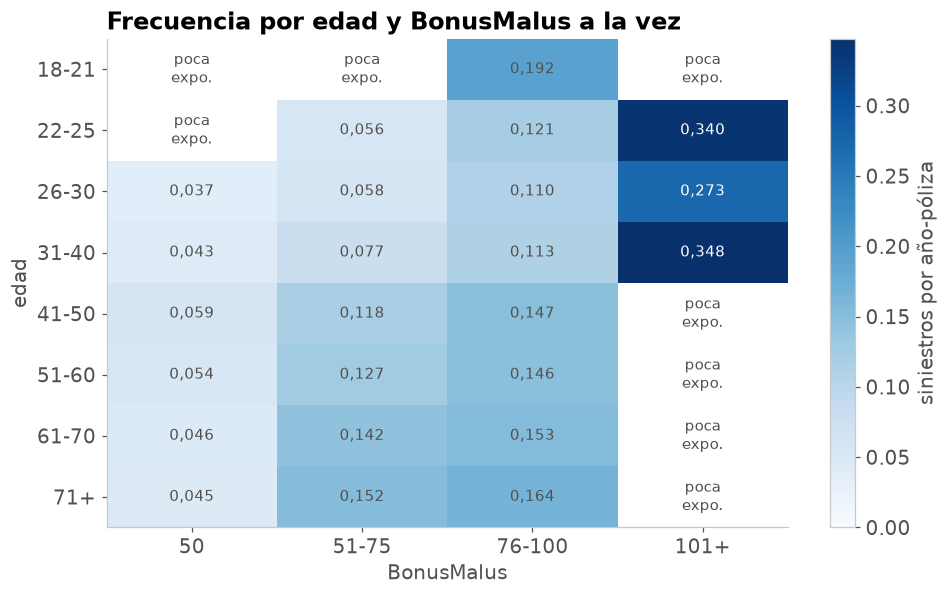

In [8]:
cruce_frec = (polizas.groupby(["franja_edad", "franja_bm"], observed=True)["claimnb"].sum()
              / polizas.groupby(["franja_edad", "franja_bm"], observed=True)["exposure"].sum()).unstack()
cruce_expo = polizas.groupby(["franja_edad", "franja_bm"], observed=True)["exposure"].sum().unstack()
print("Exposición (años-póliza) en cada celda:")
display(cruce_expo.round(0))

# Escondemos las celdas con poca exposición (< 500 años): ahí la frecuencia es ruido
MIN_EXPO = 500
visible = cruce_frec.where(cruce_expo >= MIN_EXPO)

fig, ax = plt.subplots(figsize=(9, 5.6))
im = ax.imshow(visible.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(visible.shape[1]), visible.columns)
ax.set_yticks(range(visible.shape[0]), visible.index)
for i in range(visible.shape[0]):
    for j in range(visible.shape[1]):
        v = visible.iloc[i, j]
        texto = "poca\nexpo." if pd.isna(v) else f"{v:.3f}".replace(".", ",")
        color = "white" if (not pd.isna(v) and v > 0.2) else TINTA
        ax.text(j, i, texto, ha="center", va="center", fontsize=10, color=color)
ax.set_xlabel("BonusMalus")
ax.set_ylabel("edad")
ax.set_title("Frecuencia por edad y BonusMalus a la vez")
ax.grid(False)
fig.colorbar(im, ax=ax, label="siniestros por año-póliza")
guardar(fig, "a2_cruce_edad_bm")

**Lectura:**
- Los jóvenes casi no tienen exposición en BonusMalus 50 (18–21: 248 de 4.404 años): todavía no
  "ganaron" la bonificación. Están concentrados en 76–100.
- **Con el mismo BonusMalus, la ventaja de edad se achica mucho.** En 76–100, los de 18–21 tienen
  0,19 contra 0,11–0,16 del resto: más alto, pero lejos de las ~3 veces del gráfico por edad.
- El salto grande está **entre columnas** de BonusMalus (≈ 0,04–0,06 en 50 contra ≈ 0,27–0,35 en 101+).
- Sorpresa: en 51–75 la frecuencia **sube** con la edad. Un adulto mayor con recargo probablemente
  tuvo siniestros recientes.

Conclusión: mirar una variable por vez **exagera** el efecto de la edad. Separarlos bien requiere
un modelo que mire todas las variables juntas.

### H2 — Zona y densidad: ¿más frecuencia y más severidad?

,polizas,pct_exposicion,frecuencia,severidad,rel_frecuencia,rel_severidad
area,,,,,,
A,103957,17.289,0.054,2300.723,0.736,1.016
B,75459,12.000,0.061,3370.292,0.830,1.488
C,191880,29.133,0.068,2060.069,0.921,0.909
D,151596,21.511,0.084,2243.187,1.135,0.990
E,137167,17.799,0.096,2126.336,1.301,0.939
F,17954,2.267,0.095,1524.039,1.291,0.673


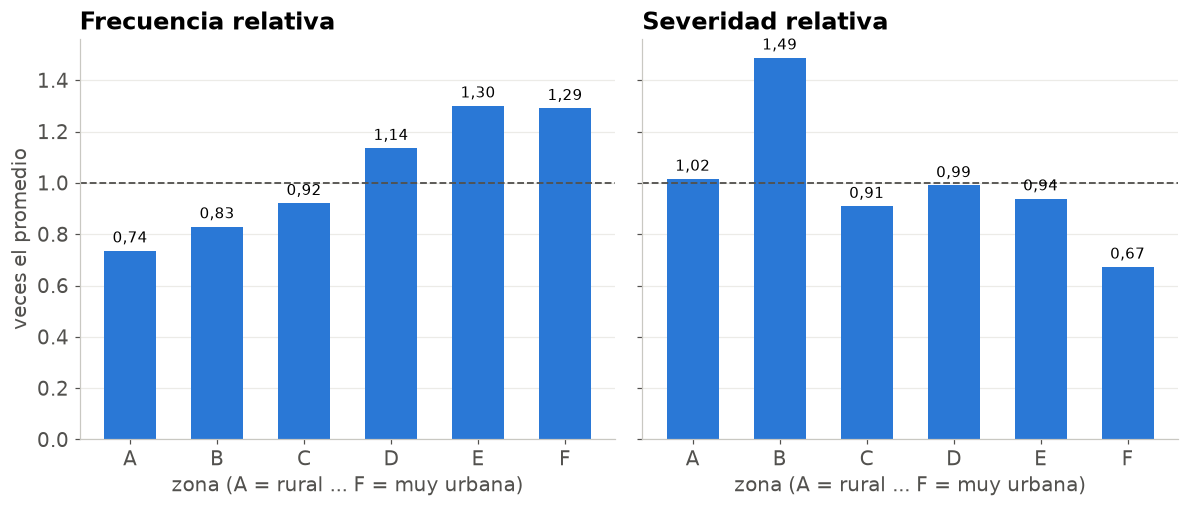

In [9]:
por_area = resumen(polizas, "area")
por_area["rel_severidad"] = por_area["severidad"] / SEV_GLOBAL
display(por_area[["polizas", "pct_exposicion", "frecuencia", "severidad", "rel_frecuencia", "rel_severidad"]].round(3))

# Dos paneles con la MISMA escala (no es doble eje: son dos gráficos lado a lado)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, col, titulo in [(axes[0], "rel_frecuencia", "Frecuencia relativa"),
                        (axes[1], "rel_severidad", "Severidad relativa")]:
    barras = ax.bar(por_area.index, por_area[col], color=AZUL, width=0.6)
    ax.axhline(1, color=TINTA, linestyle="--", linewidth=1.2)
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in por_area[col]], padding=3, fontsize=10)
    ax.set_title(titulo)
    ax.set_xlabel("zona (A = rural ... F = muy urbana)")
axes[0].set_ylabel("veces el promedio")
guardar(fig, "a2_zona_frecuencia_severidad")

**Lectura:** la frecuencia **sube** de la zona rural (A, 0,74) a la urbana (E–F, ~1,3).
La severidad **no sigue ese orden**: la zona más urbana (F) tiene la severidad más baja, y la B
la más alta. **H2 se confirma:** en la ciudad se choca más seguido, pero no más caro.
(Lo raro de la zona B lo explicamos en el Acto 3.)

---
# Acto 3 · ¿Cuánto debería costar cada perfil?

La **prima pura** junta frecuencia y severidad. Pero antes hay que mirar la severidad de cerca.

### H3 — ¿Pocos siniestros grandes dominan el costo?

El 0.1% de siniestros más caros (26) = 21.4% del monto total
El 1% de siniestros más caros (264) = 38.0% del monto total
El 5% de siniestros más caros (1,322) = 52.1% del monto total
El 10% de siniestros más caros (2,644) = 59.9% del monto total


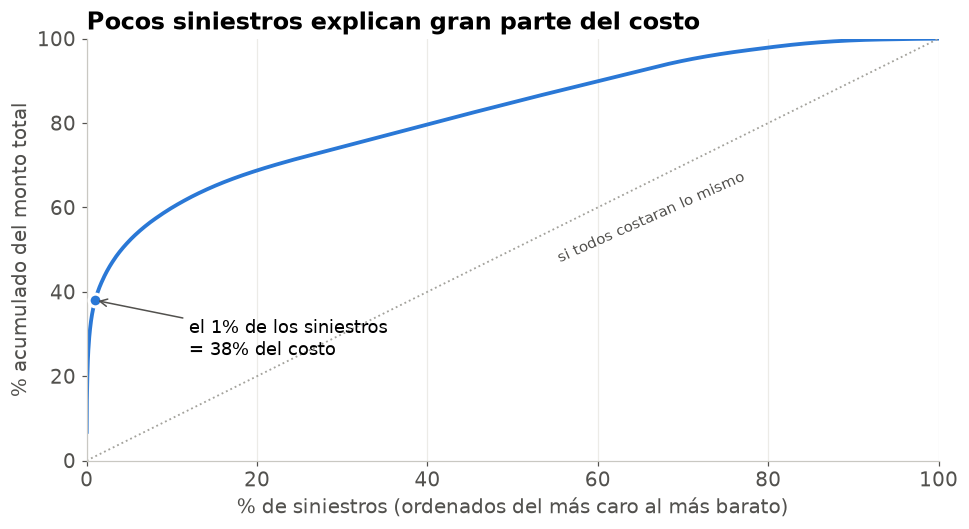

In [10]:
montos = np.sort(siniestros["claimamount"].values)[::-1]          # de mayor a menor
pct_monto_acum = 100 * np.cumsum(montos) / montos.sum()
pct_siniestros = 100 * np.arange(1, len(montos) + 1) / len(montos)

for top in [0.1, 1, 5, 10]:
    n = int(len(montos) * top / 100)
    print(f"El {top}% de siniestros más caros ({n:,}) = {pct_monto_acum[n - 1]:.1f}% del monto total")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pct_siniestros, pct_monto_acum, color=AZUL, linewidth=2.5)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle=":", linewidth=1.2)
ax.text(55, 47, "si todos costaran lo mismo", color=TINTA, fontsize=10, rotation=24)
n1 = int(len(montos) * 0.01)
ax.scatter([1], [pct_monto_acum[n1 - 1]], s=70, color=AZUL, edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"el 1% de los siniestros\n= {pct_monto_acum[n1 - 1]:.0f}% del costo".replace(".", ","),
            xy=(1, pct_monto_acum[n1 - 1]), xytext=(12, 25), fontsize=12,
            arrowprops=dict(arrowstyle="->", color=TINTA))
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("% de siniestros (ordenados del más caro al más barato)")
ax.set_ylabel("% acumulado del monto total")
ax.set_title("Pocos siniestros explican gran parte del costo")
ax.grid(axis="both")
guardar(fig, "a3_concentracion_costo")

**Lectura:** el 1 % de los siniestros más caros explica el **38 %** del costo total. **H3 se confirma.**

### ¿Quiénes tuvieron los siniestros más grandes?

In [11]:
display(siniestros.nlargest(5, "claimamount"))

,idpol,claimamount,drivage,bonusmalus,area
9756,1120377,4075400.56,19,100,B
15768,110846,1403057.40,20,100,C
11637,2141337,1301172.60,18,100,D
17992,3122016,774411.50,40,63,E
2869,2008127,390742.27,57,50,D


Los **3 siniestros más grandes** (más de 1,3 millones cada uno) son de conductores de **18 a 20 años**.
¿Qué pasa con la prima pura de esa franja?

### Recortar los siniestros extremos (tope en el percentil 99)

Práctica habitual en pricing: los montos por encima de un tope se recortan para el análisis por
perfil, porque un único siniestro de 4 millones no dice nada estable sobre un perfil.
El excedente se reparte después en toda la cartera (*suposición de diseño, no se hace en este draft*).

Tope (percentil 99): 16,451  | el recorte saca el 30.7% del monto


,sin_tope,con_tope_p99
franja_edad,,
18-21,12.97,3.56
22-25,1.39,1.69
26-30,1.00,1.11
31-40,0.89,0.93
41-50,0.79,1.00
51-60,0.77,0.93
61-70,0.71,0.81
71+,0.98,0.88


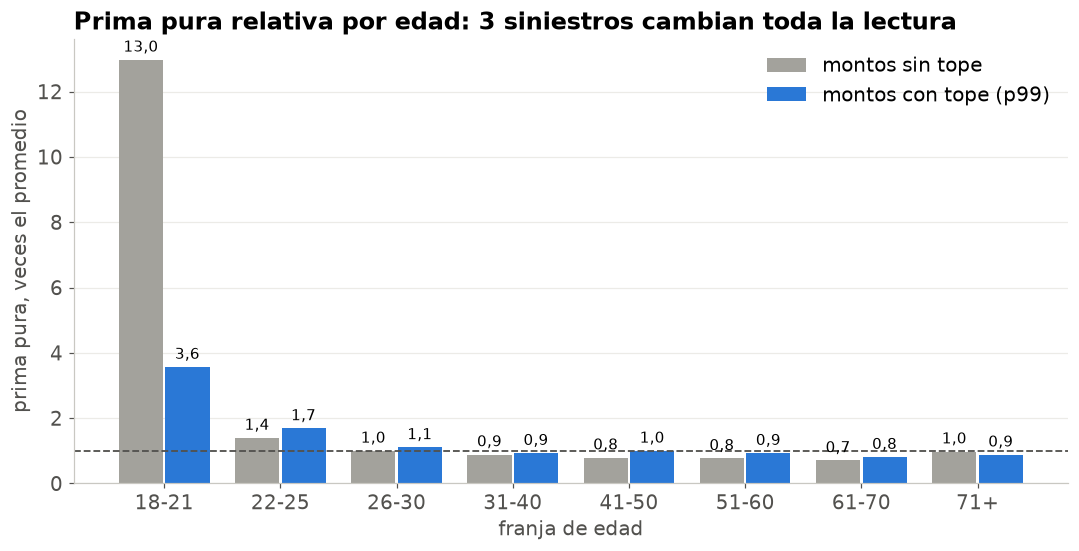

In [12]:
TOPE = np.percentile(siniestros["claimamount"], 99)
siniestros["monto_tope"] = siniestros["claimamount"].clip(upper=TOPE)
monto_tope = siniestros.groupby("idpol")["monto_tope"].sum()
polizas["monto_tope"] = polizas["idpol"].map(monto_tope).fillna(0)
excedente = 1 - polizas["monto_tope"].sum() / polizas["monto"].sum()
print(f"Tope (percentil 99): {TOPE:,.0f}  | el recorte saca el {100 * excedente:.1f}% del monto")

edad_sin = resumen(polizas, "franja_edad", "monto")
edad_con = resumen(polizas, "franja_edad", "monto_tope")
comparacion = pd.DataFrame({"sin_tope": edad_sin["rel_prima_pura"], "con_tope_p99": edad_con["rel_prima_pura"]})
display(comparacion.round(2))

x = np.arange(len(comparacion))
fig, ax = plt.subplots()
b1 = ax.bar(x - 0.2, comparacion["sin_tope"], width=0.38, color=GRIS, label="montos sin tope")
b2 = ax.bar(x + 0.2, comparacion["con_tope_p99"], width=0.38, color=AZUL, label="montos con tope (p99)")
ax.bar_label(b1, labels=[f"{v:.1f}".replace(".", ",") for v in comparacion["sin_tope"]], padding=3, fontsize=10)
ax.bar_label(b2, labels=[f"{v:.1f}".replace(".", ",") for v in comparacion["con_tope_p99"]], padding=3, fontsize=10)
ax.axhline(1, color=TINTA, linestyle="--", linewidth=1.2)
ax.set_xticks(x, comparacion.index)
ax.set_xlabel("franja de edad")
ax.set_ylabel("prima pura, veces el promedio")
ax.set_title("Prima pura relativa por edad: 3 siniestros cambian toda la lectura")
ax.legend(frameon=False)
guardar(fig, "a3_prima_pura_edad_tope")

**Lectura:** sin tope, los 18–21 parecen costar **13 veces** el promedio; con tope, **3,6 veces**.
Siguen siendo el perfil más caro, pero el número que se lleve a una tarifa tiene que ser el robusto.

### Tabla de relatividades de prima pura (con tope)

In [13]:
partes = []
for col, nombre in [("franja_edad", "Edad"), ("franja_bm", "BonusMalus"), ("area", "Zona")]:
    t = resumen(polizas, col, "monto_tope")[["pct_exposicion", "rel_frecuencia", "rel_prima_pura"]]
    t.index = [f"{nombre}: {i}" for i in t.index]
    partes.append(t)
relatividades = pd.concat(partes).round(2)
relatividades.to_csv(IMG.parent / "relatividades.csv")
relatividades

,pct_exposicion,rel_frecuencia,rel_prima_pura
Edad: 18-21,1.23,2.86,3.56
Edad: 22-25,3.30,1.69,1.69
Edad: 26-30,8.14,1.11,1.11
Edad: 31-40,23.41,0.94,0.93
Edad: 41-50,24.58,1.02,1.00
Edad: 51-60,21.12,0.94,0.93
Edad: 61-70,10.69,0.83,0.81
Edad: 71+,7.52,0.81,0.88
BonusMalus: 50,62.83,0.70,0.67
BonusMalus: 51-75,23.67,1.25,1.24


**Lectura:** los perfiles que más se apartan del promedio son **BonusMalus con recargo
(≈ 4,9×)** y **conductores de 18–21 (≈ 3,6×)**. Por zona, la urbana E cuesta ≈ 1,36× y la rural A ≈ 0,72×.
La zona B, que sin tope parecía cara, **deja de serlo**: era un siniestro.

---
# Acto 4 · ¿Qué no podemos afirmar?

- **No es tarifa:** calculamos costo esperado; no hay prima cobrada, gastos ni margen.
- **Asociación, no causa:** edad y BonusMalus se mezclan; el análisis de a una variable exagera efectos.
  Separarlos bien requiere un modelo multivariado (ej. GLM).
- **Segmentos chicos = números inestables:** 18–21 es el 1 % de la exposición.
- **El tope cambia los resultados:** elegimos el percentil 99; otro tope daría otras relatividades.
- **Datos:** solo RC, sin fechas, marca anonimizada, montos que incluyen reservas, 195 siniestros
  sin póliza (más caros que el promedio) que no se pueden asignar a ningún perfil, y falta Lorraine.